# Microscopy Analysis

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from cdk.analysis import cell as m

## Load data

In [ ]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Overwriting drive_utils.py


In [ ]:
# Set use_drive = True to download platemap.csv from Google Drive instead of using a local file.
# The Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/17T9CJkq3yOF23OkPDqcOclaWpDAu1YkS/view?usp=sharing",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    PLATEMAP_PATH = downloaded_paths["platemap.csv"]
else:
    PLATEMAP_PATH = "platemap.csv"

print(f"Platemap file: {PLATEMAP_PATH}")

Platemap file: data/platemap.csv


In [ ]:
ZARR_URL = "https://data.nucleus.engineering/microscopy/valine/820-720-620-520-420_2026-08-26_12-32-14.888144.zarr"
PARQUET_URL = "https://data.nucleus.engineering/microscopy/valine/820-720-620-520-420_2026-08-26_12-32-14.888144.parquet"

data = m.load(PARQUET_URL, PLATEMAP_PATH) #, sample=5000)

## Check Cell Segmentation
Optionally check cells - - will take a few seconds since this reads from a zarr file! If you want faster, load the zarr specifically into this folder. Dont use a URL.

,Label,Area (um^2),Diameter (Equivalent) (um),Diameter (Feret) (um),Length Major (um),Length Minor (um),Perimeter (um),Intensity Mean (GFP),Intensity Mean (Alexa Fluor 647),Intensity Max (GFP),...,Intensity Norm (Alexa Fluor 647),Timepoint,Dataset,Well,Date,Experiment,Full_Name,Type,Name,Osmolarity (mM)
1220165,21811,40.150784,7.149935,8.574119,7.638847,6.752329,22.666886,2345.267606,2584.098592,3730.0,...,13.502191,1,/storage/storage/microscopy/valine/820-720-620...,K17,2026-08-26,20260826-Diff lipids with diff osmolarity,720 mM - POPC + Chol + EggSM,Sample,POPC + Chol + EggSM,720
2059318,25612,16.965120,4.647651,5.044569,4.881247,4.356699,12.837443,904.366667,3338.800000,954.0,...,63.517179,6,/storage/storage/microscopy/valine/820-720-620...,K18,2026-08-26,20260826-Diff lipids with diff osmolarity,620 mM - POPC + Chol + EggSM,Sample,POPC + Chol + EggSM,620
709023,17189,23.751168,5.499175,6.933097,6.236931,4.926764,17.220420,1097.690476,3463.095238,1298.0,...,39.771611,0,/storage/storage/microscopy/valine/820-720-620...,K16,2026-08-26,20260826-Diff lipids with diff osmolarity,820 mM - POPC + Chol + EggSM,Sample,POPC + Chol + EggSM,820
1776343,22227,37.888768,6.945609,7.851110,7.454879,6.480769,21.162886,877.850746,3577.686567,925.0,...,20.392608,1,/storage/storage/microscopy/valine/820-720-620...,K18,2026-08-26,20260826-Diff lipids with diff osmolarity,620 mM - POPC + Chol + EggSM,Sample,POPC + Chol + EggSM,620


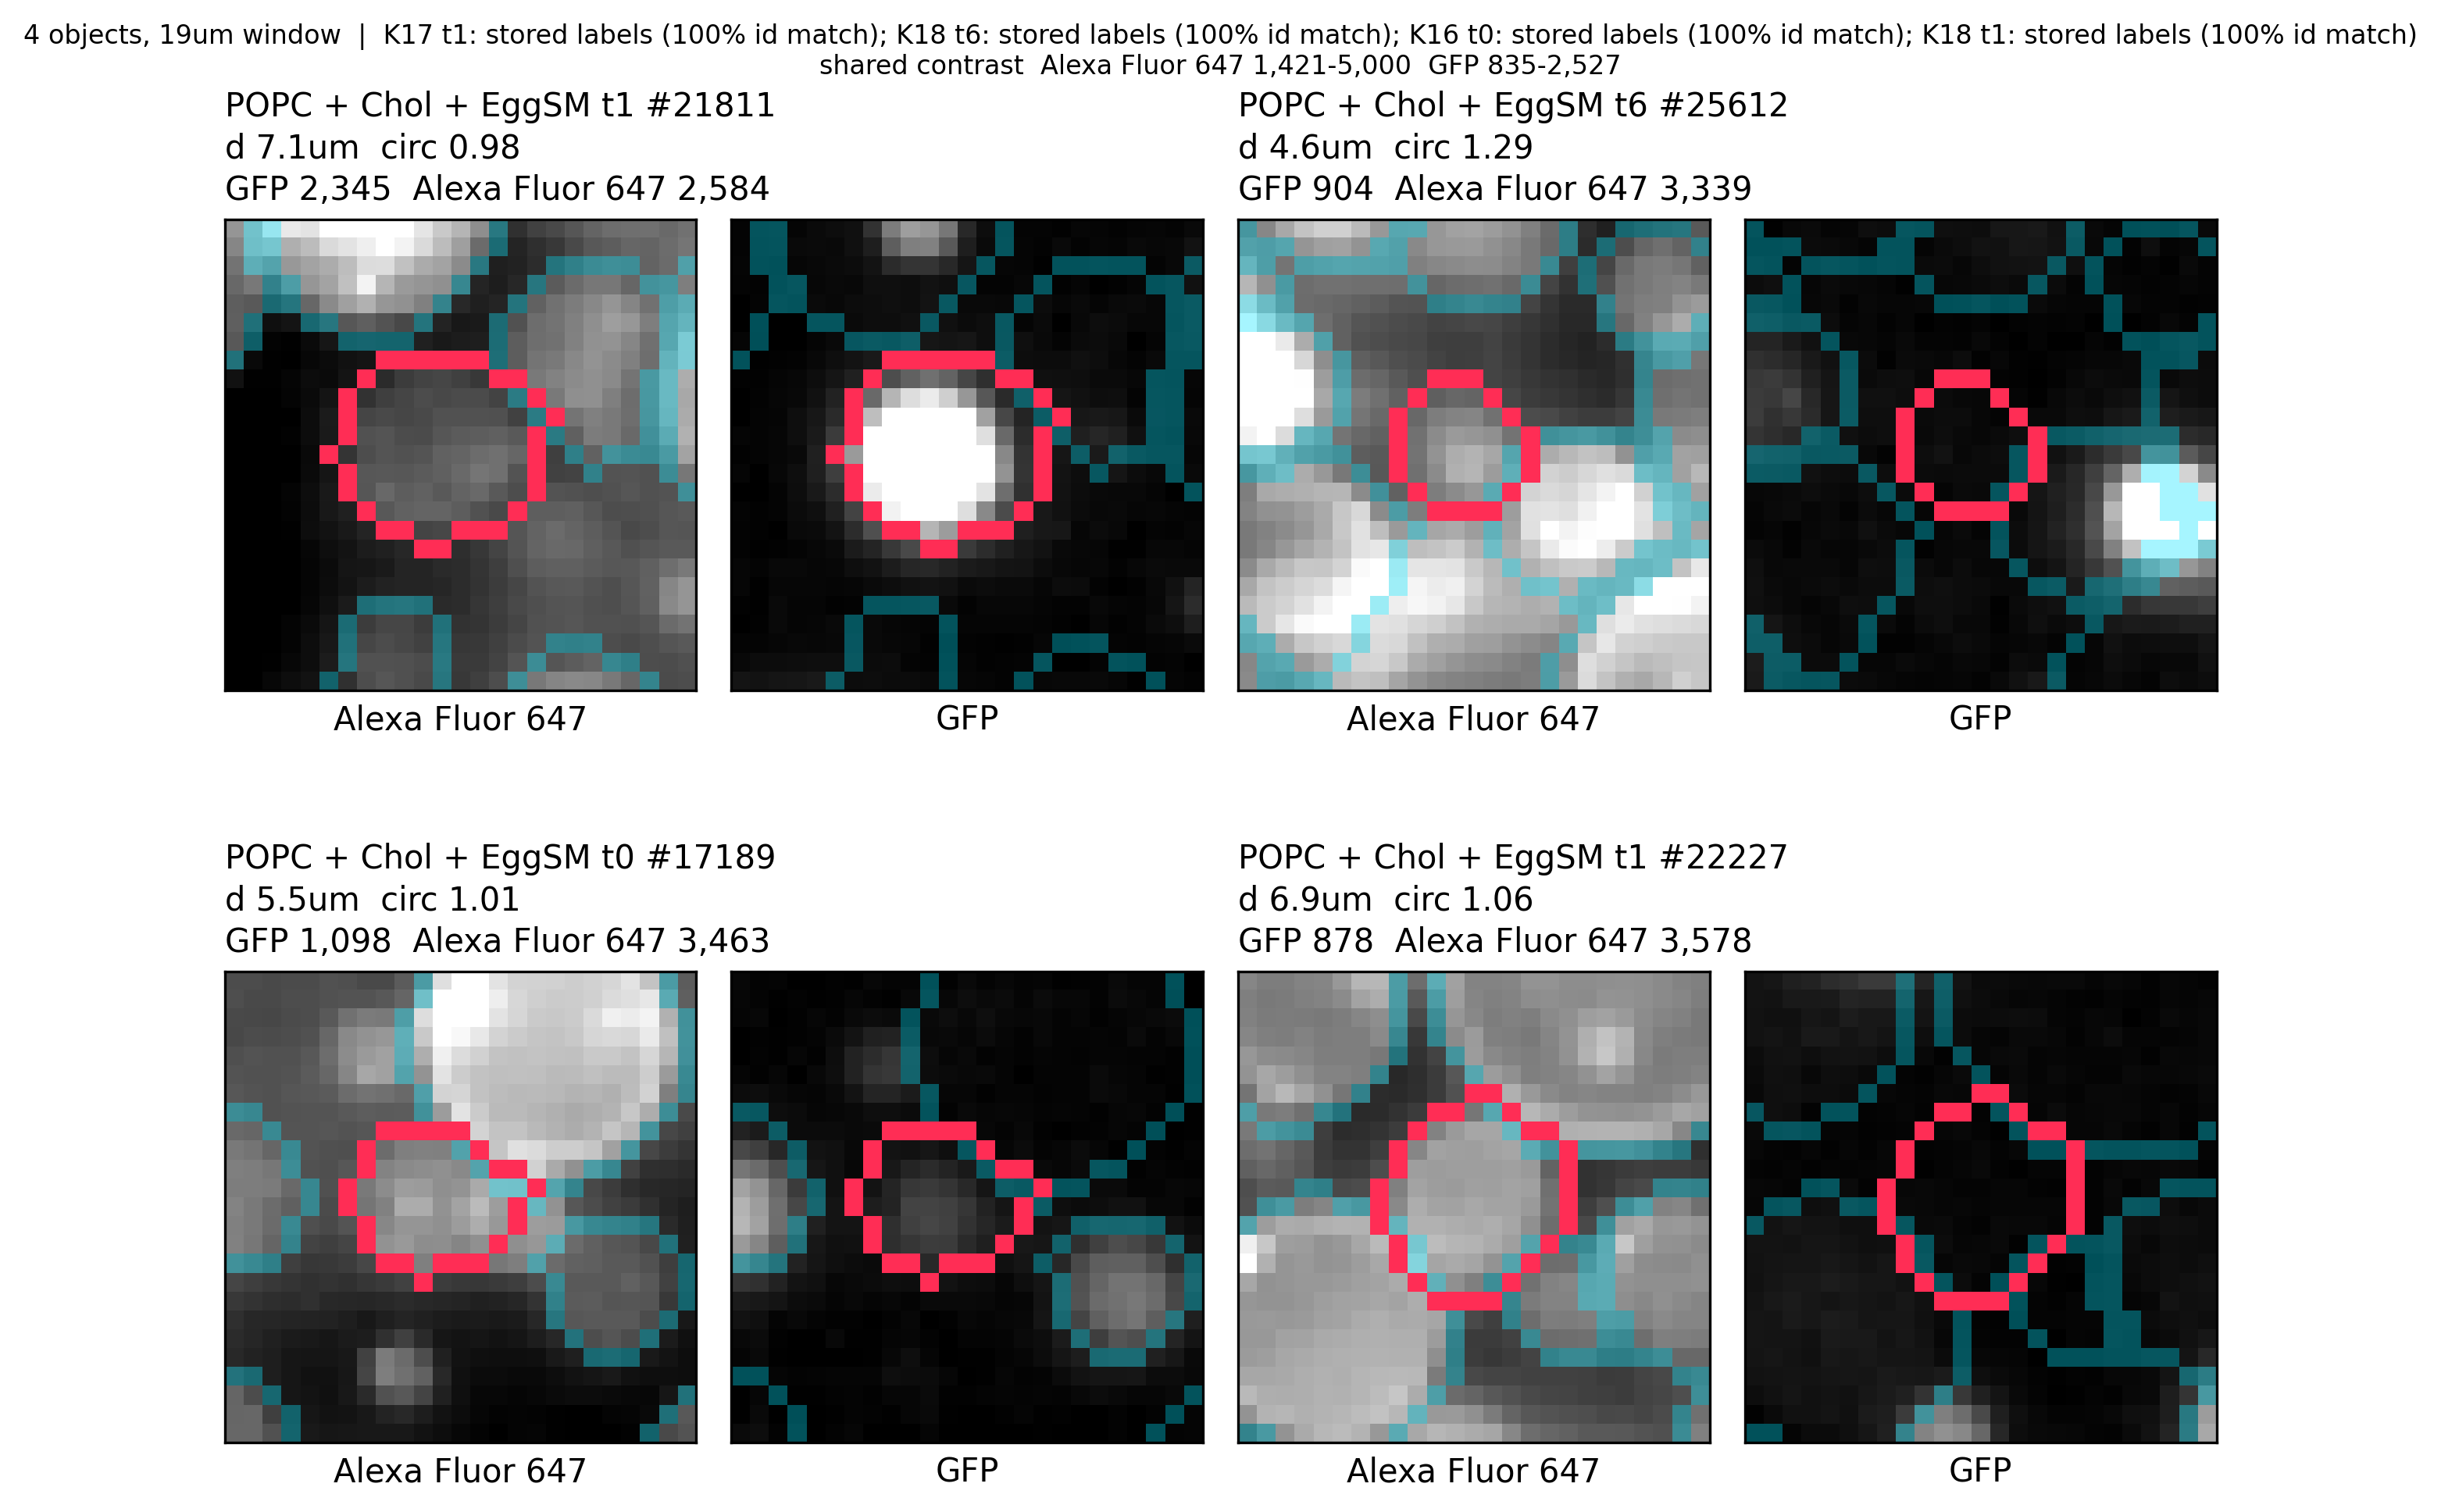

In [ ]:
NUM_CELLS_TO_CHECK = 4
m.plot_cell_grid(data, ZARR_URL, n=NUM_CELLS_TO_CHECK, pyramid_level=2)
# example_indexed_data = data[(data.Well == data.Well.unique()[0]) & (data.Timepoint == 0)]
# m.plot_cell_grid(example_indexed_data, ZARR_URL, n=5, channels=["Alexa Fluor 647"], pyramid_level=2) #show just one channel channels
# m.plot_cell_grid(one, ZARR_URL, n=NUM_CELLS_TO_CHECK, contrast="tile", pyramid_level=2) #make the intensity contrast scaled by tile not by the whole grid




## Summary Plots

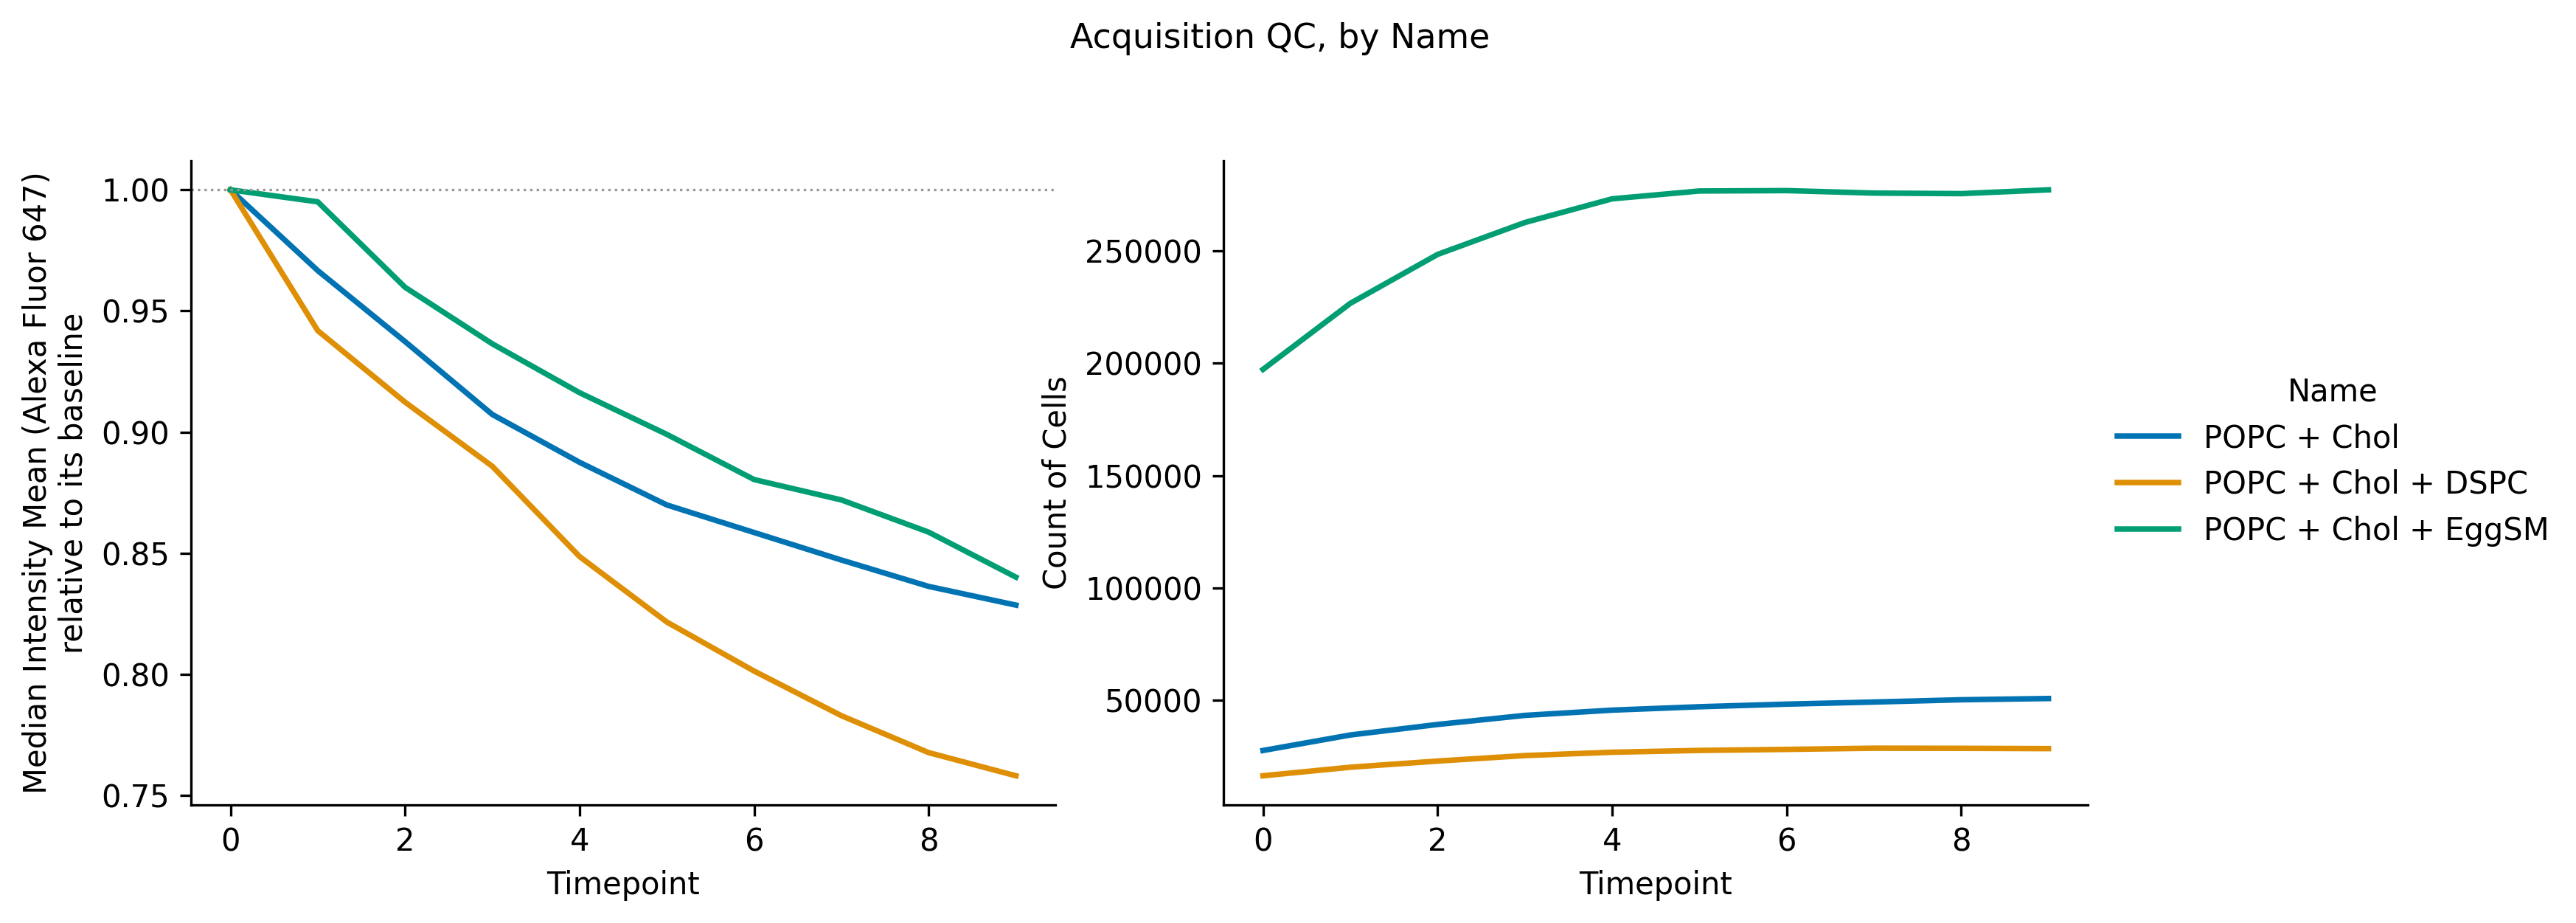

In [ ]:
_ = m.plot_qc(data, hue="Name") #facet="other_col"

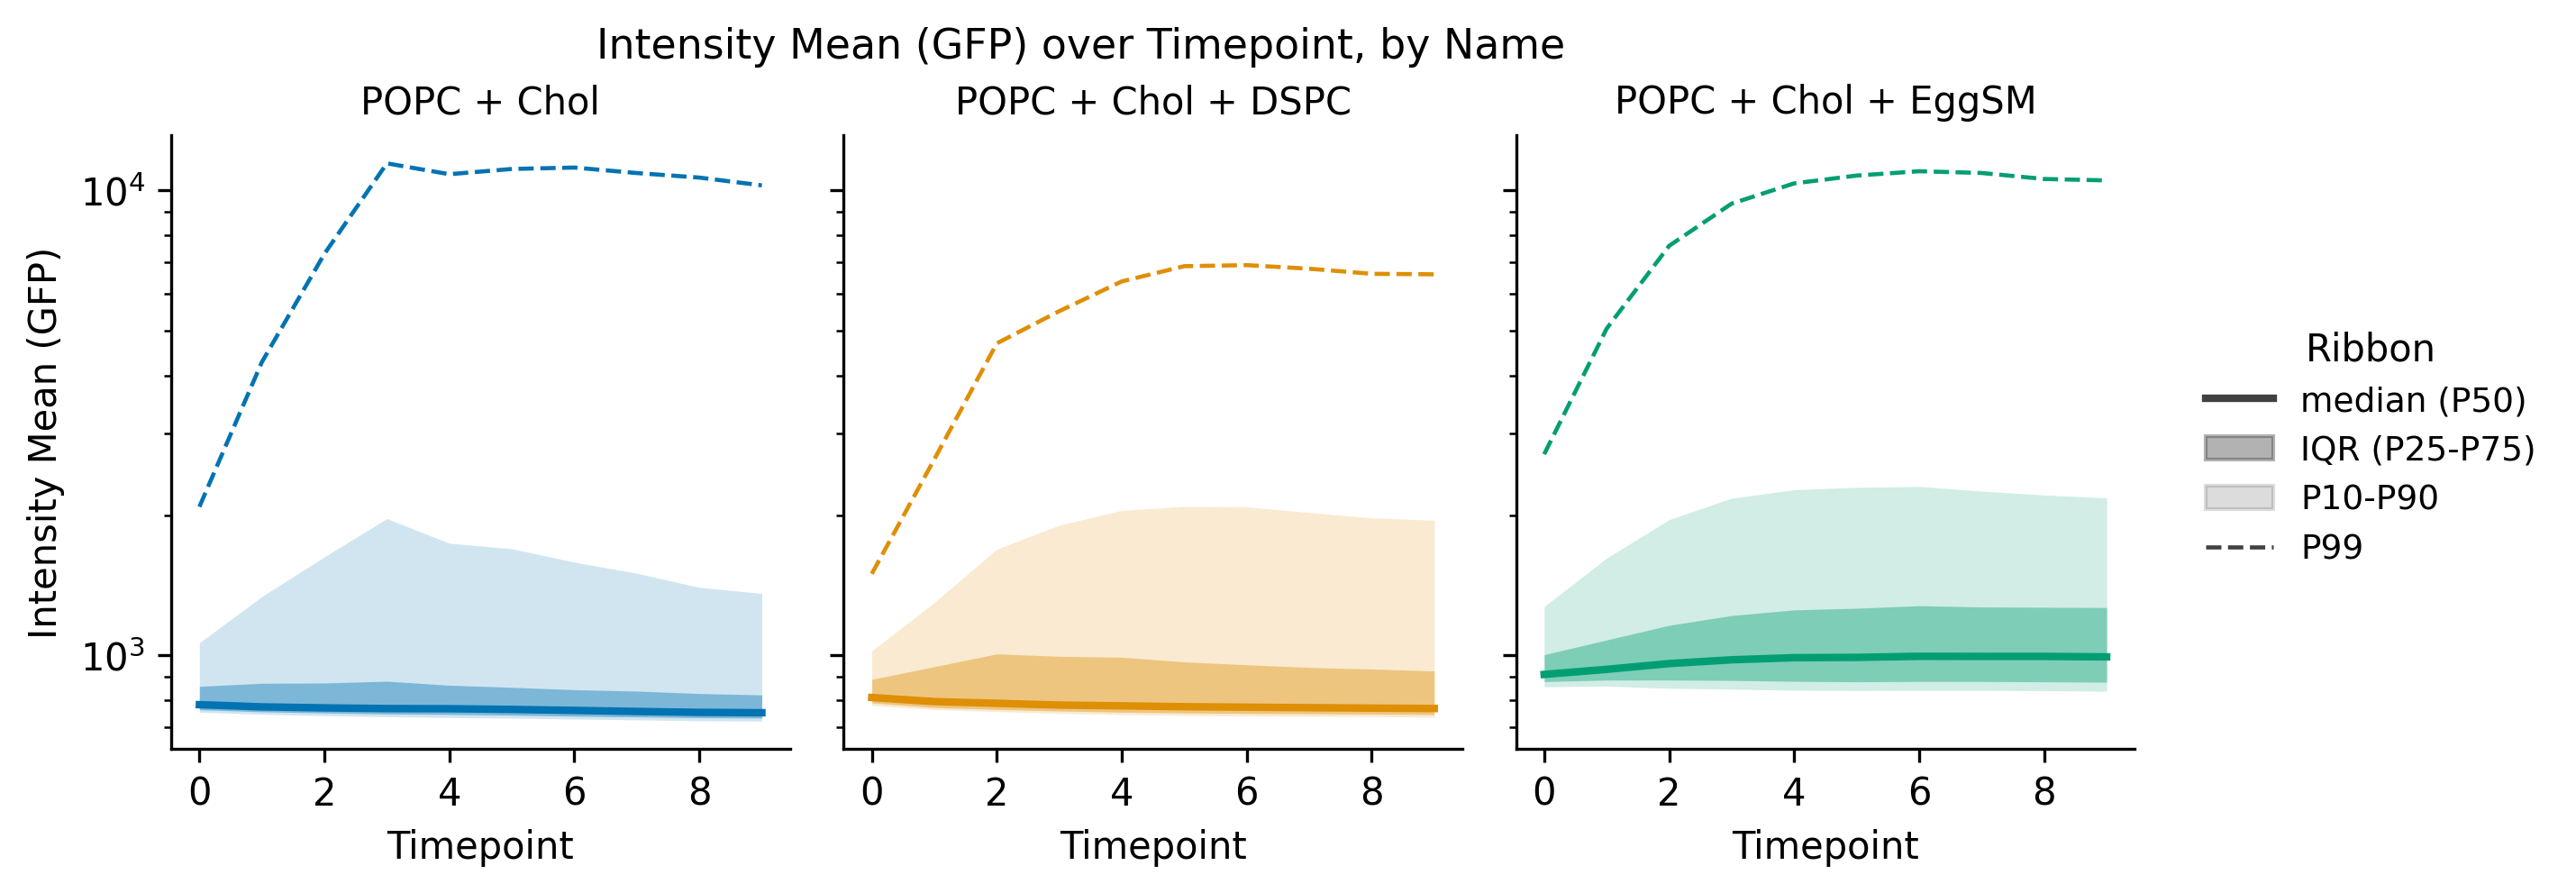

In [ ]:
_ = m.plot_quantile_ribbon(data, hue="Name") #facet="other_col"

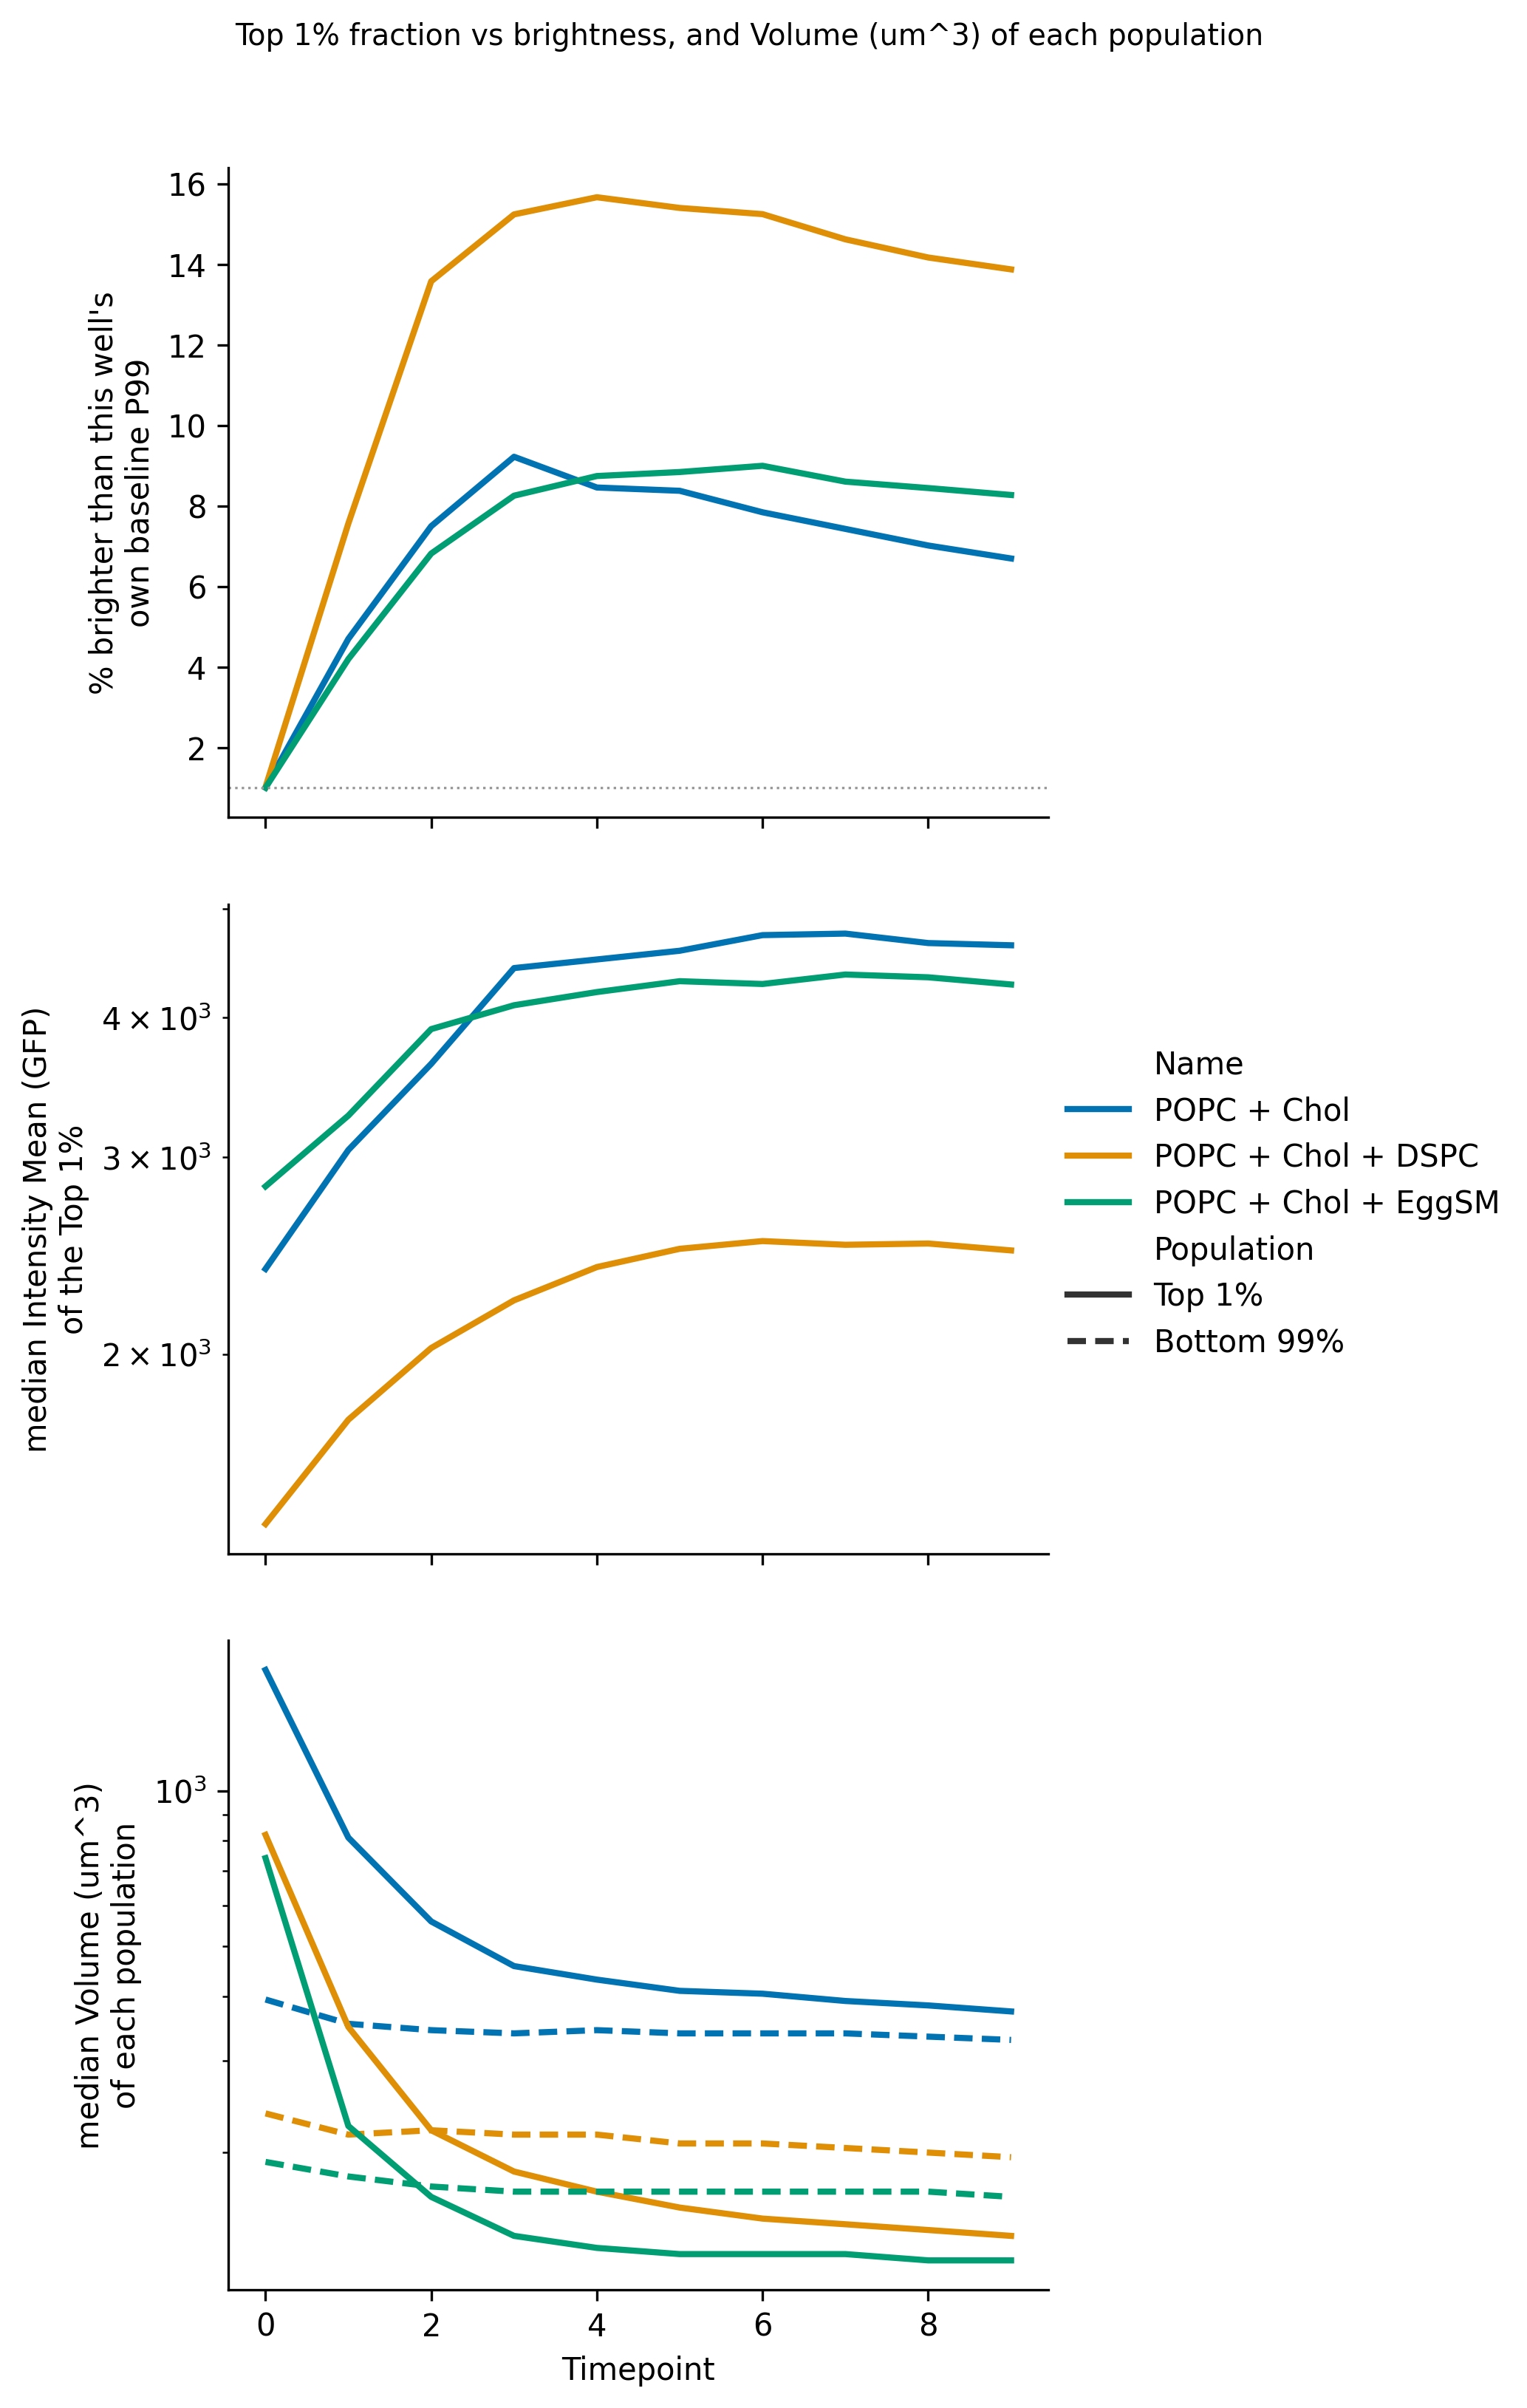

In [ ]:
# how many cells turn on, and how bright did they get.Default shows the 99th percentaile
_ = m.plot_positive_fraction(data, gate_quantile=0.99, hue="Name") #,facet="other_col"

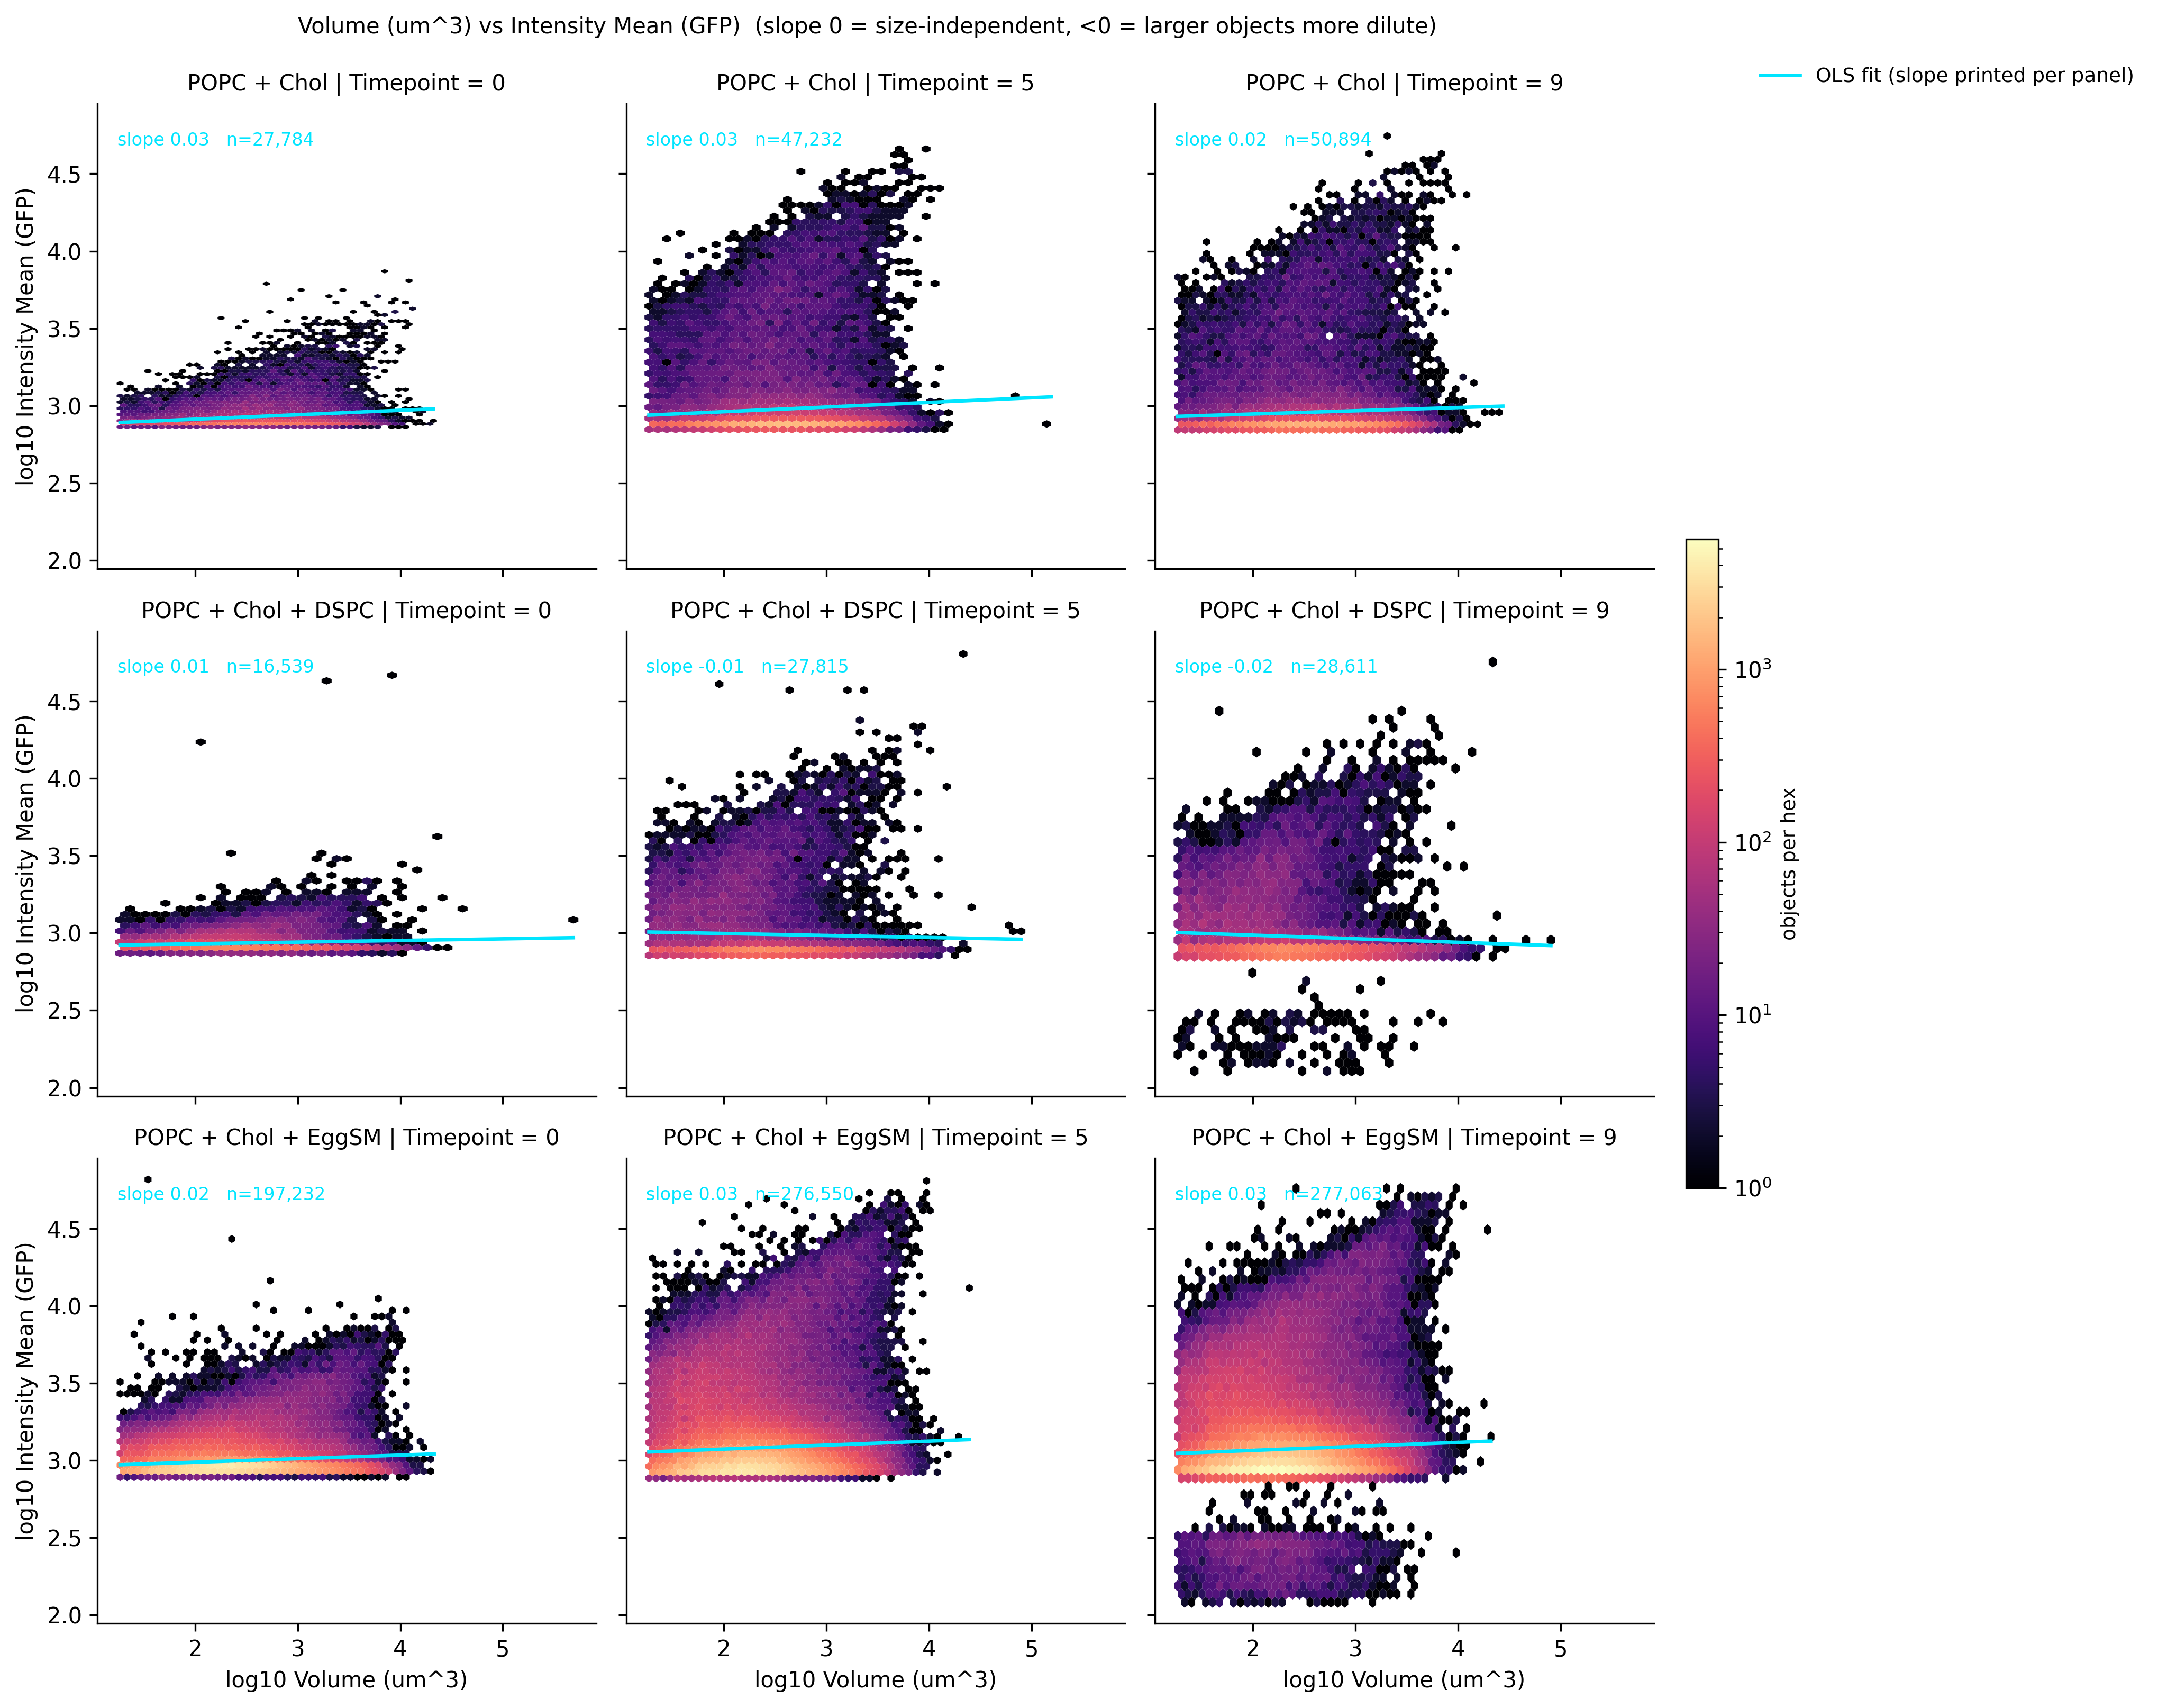

In [ ]:
_ = m.plot_size_expression(data, facet="Name") #, timepoints=[1,3,5,7,9], facet="other_col")

## Old To be deprecated plotting functions

In [ ]:
_ = m.plot_summary(data)

In [ ]:
_ = m.plot_size(data)

## Fogplots

In [ ]:
_ = m.plot_fogplot(data)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
_ = m.plot_fogplot_compare(data)

Output hidden; open in https://colab.research.google.com to view.

In [3]:
%pip install zarr
%pip install cmap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 995.9/995.9 kB 11.7 MB/s eta 0:00:00


In [4]:
import zarr
import matplotlib.pyplot as plt
from cmap import Colormap
import numpy as np

url = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/201009o_EsaR_mNG_0.1_0.5_K_L_2026-10-09_19-47-50.861429.zarr"
root = zarr.open_group(url, mode="r")
print(list(root.keys()))


['K', 'L']


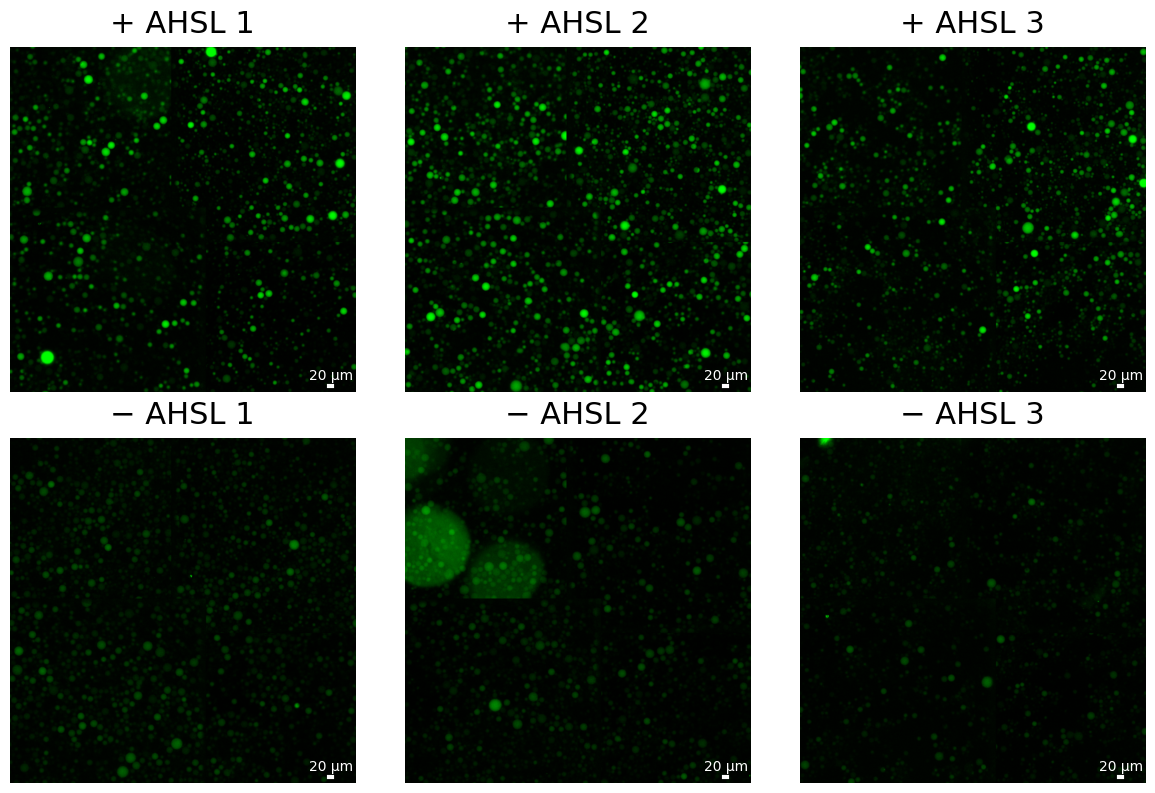

In [5]:
#| label: microscopy-exp-01

from matplotlib.colors import LinearSegmentedColormap

gfp = LinearSegmentedColormap.from_list("gfp", ["black", "lime"])

wells = {
    ("K", "18"): "+ AHSL 1",
    ("K", "19"): "+ AHSL 2",
    ("K", "20"): "+ AHSL 3",
    ("L", "18"): "− AHSL 1",
    ("L", "19"): "− AHSL 2",
    ("L", "20"): "− AHSL 3",
}

TITLE_FONTSIZE = 22   # raise or lower to taste

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

y0, y1 = 4000, 7000
x0, x1 = 4000, 7000

px_um = 0.666  # µm per pixel at s1
bar_um = 20   # bar length in µm
bar_px = bar_um / px_um

for ax, ((row, col), name) in zip(axes, wells.items()):
    img = root[row][col]["0"]["s0"][-1, 0, 0, y0:y1, x0:x1]  # last timepoint, channel 0, z 0
    ax.imshow(img, cmap=gfp, vmin=1200, vmax=4500)
    ax.set_title(name, fontsize=TITLE_FONTSIZE, pad=10)
    ax.axis("off")
    x_end = (x1 - x0) - 200    # smaller number = closer to the right edge
    x_start = x_end - bar_px
    y_bar = (y1 - y0) - 50   # smaller number = closer to the bottom edge
    ax.plot([x_start, x_end], [y_bar, y_bar], color="white", lw=3)
    ax.text((x_start + x_end) / 2, y_bar - 60, f"{bar_um} µm", color="white", ha="center")

plt.tight_layout()
#plt.save_fig("MB_EsaR_GUVs_AHSL.png", dpi=600)

plt.show()